# Development of a Machine Learning-Based Maize Leaf Disease Classification System for Zimbabwean Farmers

## Stage 1: Problem Definition

### 1.1 Problem Statement

Maize diseases can reduce crop yields and affect farmers' income. Identifying diseases from leaf images can be difficult because different diseases may produce similar symptoms.

This project addresses the problem by developing a machine learning system that analyses maize leaf images and classifies them into disease categories or identifies them as healthy.

### 1.2 Project Aim

To develop and evaluate a machine learning-based system that classifies maize leaf images into four categories: Blight, Common Rust, Gray Leaf Spot, and Healthy.

### 1.3 Machine Learning Problem

This project is a supervised image classification task.

- **Input:** An image of a maize leaf.
- **Target:** The class assigned to the image.
- **Classes:** Blight, Common Rust, Gray Leaf Spot, and Healthy.
- **Output:** The predicted class for the input image.

The model learns patterns from labelled maize leaf images and uses those patterns to predict the class of an image it has not seen before.

### 1.4 Justification for Using Machine Learning

A rule-based system would require manually defining symptoms and conditions for each disease. This can be difficult because leaf appearance varies with lighting, image quality, and disease severity.

Machine learning can learn visual patterns from labelled examples and apply them to new images. This makes it suitable for developing a maize leaf classification system, although its predictions may not always be correct.

## Stage 2: Dataset Acquisition and Understanding

### 2.1 Dataset Description

The dataset contains maize leaf images organised into four labelled classes: Blight, Common Rust, Gray Leaf Spot, and Healthy. Each image belongs to a class folder, allowing the folder name to be used as its target label for supervised machine learning.

## Project Setup: Libraries and Environment

Import the Python libraries required for data analysis, image processing, visualisation, and machine learning. Display the Python and library versions to help document the project environment and support reproducibility.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from PIL import Image

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("All required libraries imported successfully!")

Python version: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
NumPy version: 2.4.6
Pandas version: 3.0.6
Scikit-learn version: 1.9.1
All required libraries imported successfully!


### Project Directory Verification

Check the current working directory and confirm whether the project folder exists. Display the files and folders inside it to verify the project location.

In [2]:
from pathlib import Path
import os

# Display the folder where this notebook is running
print("Current working directory:")
print(Path.cwd())

# Check the project folder
project_dir = Path.home() / "Documents" / "MaizeLeafDiseaseProject"

print("\nProject folder exists:", project_dir.exists())
print("Project folder path:", project_dir)

# Display the items inside the project folder
if project_dir.exists():
    print("\nItems inside the project folder:")
    for item in project_dir.iterdir():
        print(item.name, " - ", "Folder" if item.is_dir() else "File")
else:
    print("\nThe project folder was not found at the expected location.")

Current working directory:
C:\Users\USER\OneDrive\Documents\MaizeLeafDiseaseProject

Project folder exists: False
Project folder path: C:\Users\USER\Documents\MaizeLeafDiseaseProject

The project folder was not found at the expected location.


### 2.1 Dataset Location and Structure

Identify the project dataset directory and verify that it contains the expected class folders. The dataset is organised into separate folders representing the four maize leaf categories: Blight, Common Rust, Gray Leaf Spot, and Healthy.

In [3]:
from pathlib import Path

# Correct project location
project_dir = (
    Path.home()
    / "OneDrive"
    / "Documents"
    / "MaizeLeafDiseaseProject"
)

# Dataset location
data_dir = project_dir / "data"

print("Project folder exists:", project_dir.exists())
print("Dataset folder exists:", data_dir.exists())
print("\nFolders inside the data directory:")

if data_dir.exists():
    for folder in data_dir.iterdir():
        if folder.is_dir():
            print("-", folder.name)
else:
    print("Dataset folder not found. Please check its location.")

Project folder exists: True
Dataset folder exists: True

Folders inside the data directory:
- Blight
- Common_Rust
- Gray_Leaf_Spot
- Healthy


### 2.2 Dataset Size and Class Counts

Count the image files in each class folder and calculate the total dataset size. This provides an initial overview of the dataset and helps identify possible differences in the number of images available for each class.

In [4]:
from pathlib import Path
import pandas as pd

data_dir = (
    Path.home()
    / "OneDrive"
    / "Documents"
    / "MaizeLeafDiseaseProject"
    / "data"
)

# Common image file formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_counts = []

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        images = [
            file for file in folder.rglob("*")
            if file.is_file()
            and file.suffix.lower() in image_extensions
        ]

        class_counts.append({
            "Disease Class": folder.name,
            "Number of Images": len(images)
        })

class_df = pd.DataFrame(class_counts)

display(class_df)

print("\nTotal images:", class_df["Number of Images"].sum())

,Disease Class,Number of Images
0,Blight,1144
1,Common_Rust,1306
2,Gray_Leaf_Spot,572
3,Healthy,1162



Total images: 4184


### 2.3 Image Quality and Properties

Inspect the dataset images to identify unreadable files and record each image's class, filename, dimensions, and format. Summarise the image dimensions and file formats to understand the dataset's characteristics and identify potential data quality issues before preprocessing.

In [5]:
from pathlib import Path
from PIL import Image
import pandas as pd

# Dataset location
data_dir = (
    Path.home()
    / "OneDrive"
    / "Documents"
    / "MaizeLeafDiseaseProject"
    / "data"
)

# Image formats to include
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_records = []
unreadable_images = []

# Inspect every image
for class_folder in sorted(data_dir.iterdir()):
    if not class_folder.is_dir():
        continue

    for image_path in class_folder.rglob("*"):
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in image_extensions:
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()

            # Reopen after verify to read its dimensions
            with Image.open(image_path) as img:
                width, height = img.size
                image_format = img.format

            image_records.append({
                "class": class_folder.name,
                "filename": image_path.name,
                "path": str(image_path),
                "width": width,
                "height": height,
                "format": image_format
            })

        except Exception as error:
            unreadable_images.append({
                "filename": image_path.name,
                "class": class_folder.name,
                "error": str(error)
            })

# Store inspection results in DataFrames
images_df = pd.DataFrame(image_records)
unreadable_df = pd.DataFrame(unreadable_images)

print("Images successfully inspected:", len(images_df))
print("Unreadable images:", len(unreadable_df))

print("\nImage counts by class:")
display(
    images_df["class"]
    .value_counts()
    .sort_index()
    .rename_axis("Disease Class")
    .reset_index(name="Image Count")
)

print("\nImage dimensions summary:")
display(
    images_df[["width", "height"]].describe().round(1)
)

print("\nImage formats:")
display(images_df["format"].value_counts())

if len(unreadable_df) > 0:
    print("\nFirst unreadable images:")
    display(unreadable_df.head(10))
else:
    print("\nNo unreadable images were detected.")

Images successfully inspected: 4184
Unreadable images: 0

Image counts by class:


,Disease Class,Image Count
0,Blight,1144
1,Common_Rust,1306
2,Gray_Leaf_Spot,572
3,Healthy,1162



Image dimensions summary:


,width,height
count,4184.0,4184.0
mean,305.9,296.6
std,278.3,248.6
min,180.0,116.0
25%,256.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,5184.0,5184.0



Image formats:


format
JPEG    4179
PNG        4
MPO        1
Name: count, dtype: int64


No unreadable images were detected.


CHECKING FOR DUPLICATES


In [6]:

from pathlib import Path
from collections import defaultdict
from PIL import Image
import hashlib
import pandas as pd

# 1. Set the dataset folder
DATA_DIR = Path(
    r"C:\Users\USER\OneDrive\Documents\MaizeLeafDiseaseProject\data"
)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff", ".mpo"
}

# 2. Find image files inside the four class folders
image_files = [
    path
    for path in DATA_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
]

print("Total image files found:", len(image_files))

# 3. Calculate two hashes for each image:
#    - File hash: detects identical files
#    - Pixel hash: detects identical decoded images
records = []

for path in image_files:
    try:
        file_hash = hashlib.sha256(path.read_bytes()).hexdigest()

        with Image.open(path) as img:
            img.load()
            rgb = img.convert("RGB")
            pixel_hash = hashlib.sha256(
                str(rgb.size).encode() + rgb.tobytes()
            ).hexdigest()
            width, height = rgb.size

        # The immediate parent folder is treated as the class name.
        class_name = path.parent.name

        records.append({
            "image_path": str(path),
            "filename": path.name,
            "class_name": class_name,
            "width": width,
            "height": height,
            "file_hash": file_hash,
            "pixel_hash": pixel_hash
        })

    except Exception as error:
        print(f"Could not inspect {path}: {error}")

image_audit_df = pd.DataFrame(records)

print("Images successfully inspected:", len(image_audit_df))

# 4. Find groups of identical files or pixel data
def find_duplicate_groups(df, hash_column):
    groups = []

    for hash_value, group in df.groupby(hash_column):
        if len(group) > 1:
            groups.append(group)

    return groups

file_duplicate_groups = find_duplicate_groups(
    image_audit_df, "file_hash"
)

pixel_duplicate_groups = find_duplicate_groups(
    image_audit_df, "pixel_hash"
)

print("\nEXACT FILE DUPLICATES")
print("Duplicate groups:", len(file_duplicate_groups))
print(
    "Images involved:",
    sum(len(group) for group in file_duplicate_groups)
)

print("\nIDENTICAL IMAGE PIXELS")
print("Duplicate groups:", len(pixel_duplicate_groups))
print(
    "Images involved:",
    sum(len(group) for group in pixel_duplicate_groups)
)

# 5. Create a review table for identical pixel images
duplicate_rows = []

for group_number, group in enumerate(pixel_duplicate_groups, start=1):
    class_names = sorted(group["class_name"].unique())

    for _, row in group.iterrows():
        duplicate_rows.append({
            "duplicate_group": group_number,
            "filename": row["filename"],
            "class_name": row["class_name"],
            "width": row["width"],
            "height": row["height"],
            "image_path": row["image_path"],
            "classes_in_group": ", ".join(class_names),
            "cross_class_duplicate": len(class_names) > 1
        })

duplicates_df = pd.DataFrame(duplicate_rows)

if not duplicates_df.empty:
    print("\nDUPLICATE IMAGE REVIEW TABLE")
    display(duplicates_df)

    duplicates_df.to_csv(
        DATA_DIR.parent / "exact_duplicate_review.csv",
        index=False
    )
    print(
        "\nReview file saved to:",
        DATA_DIR.parent / "exact_duplicate_review.csv"
    )
else:
    print("\nNo identical-pixel duplicate groups were found.")

# 6. Count duplicate groups spanning different classes
cross_class_groups = 0

for group in pixel_duplicate_groups:
    if group["class_name"].nunique() > 1:
        cross_class_groups += 1

print("\nDuplicate groups spanning multiple classes:", cross_class_groups)


Total image files found: 4184
Images successfully inspected: 4184

EXACT FILE DUPLICATES
Duplicate groups: 0
Images involved: 0

IDENTICAL IMAGE PIXELS
Duplicate groups: 0
Images involved: 0

No identical-pixel duplicate groups were found.

Duplicate groups spanning multiple classes: 0


In [7]:

from pathlib import Path
from PIL import Image
import hashlib
import shutil

# Dataset location
PROJECT_DIR = Path(
    r"C:\Users\USER\OneDrive\Documents\MaizeLeafDiseaseProject"
)
DATA_DIR = PROJECT_DIR / "data"

# Keep quarantined files OUTSIDE the data folder
QUARANTINE_DIR = (
    PROJECT_DIR / "data_cleaning_review" / "conflicting_duplicates"
)

# The two pairs confirmed by your duplicate report
duplicate_pairs = [
    ("Corn_Blight (1104).jpg", "Corn_Gray_Spot (564).jpg"),
    ("Corn_Blight (77).jpg", "Corn_Gray_Spot (19).jpg"),
]

def pixel_hash(path):
    """Hash decoded RGB pixels to compare image content."""
    with Image.open(path) as image:
        image.load()
        rgb = image.convert("RGB")
        content = str(rgb.size).encode() + rgb.tobytes()
        return hashlib.sha256(content).hexdigest()

# 1. Verify all four files exist and each pair is identical.
files_to_quarantine = []

for blight_name, gray_name in duplicate_pairs:
    blight_path = DATA_DIR / "Blight" / blight_name
    gray_path = DATA_DIR / "Gray_Leaf_Spot" / gray_name

    if not blight_path.is_file() or not gray_path.is_file():
        raise FileNotFoundError(
            f"Expected duplicate pair not found:\n"
            f"{blight_path}\n{gray_path}\n"
            "No files have been moved by this cell."
        )

    if pixel_hash(blight_path) != pixel_hash(gray_path):
        raise ValueError(
            f"Images no longer match: {blight_name} and {gray_name}. "
            "No files have been moved by this cell."
        )

    files_to_quarantine.extend([blight_path, gray_path])

# 2. Avoid overwriting any existing quarantined files.
QUARANTINE_DIR.mkdir(parents=True, exist_ok=True)

for path in files_to_quarantine:
    destination = QUARANTINE_DIR / path.parent.name / path.name
    if destination.exists():
        raise FileExistsError(
            f"Quarantine destination already exists: {destination}\n"
            "No files have been moved by this cell."
        )

# 3. Move the four files out of the dataset.
moved_files = []

try:
    for path in files_to_quarantine:
        destination = QUARANTINE_DIR / path.parent.name / path.name
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(path), str(destination))
        moved_files.append((path, destination))

except Exception:
    # Restore any files already moved if an error occurs.
    for original_path, destination in reversed(moved_files):
        if destination.exists():
            original_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.move(str(destination), str(original_path))
    raise

print("Cleaning completed successfully.")
print("Conflicting duplicate files moved:", len(moved_files))
print("Quarantine location:", QUARANTINE_DIR)

for original_path, destination in moved_files:
    print(f"Moved: {original_path.name} from {original_path.parent.name}")

# 4. Count remaining images in each class.
from collections import Counter

valid_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff", ".mpo"
}

class_counts = {}

for class_dir in sorted(DATA_DIR.iterdir()):
    if class_dir.is_dir():
        class_counts[class_dir.name] = sum(
            1 for path in class_dir.rglob("*")
            if path.is_file() and path.suffix.lower() in valid_extensions
        )

print("\nUPDATED DATASET COUNTS")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

print("Total remaining images:", sum(class_counts.values()))


FileNotFoundError: Expected duplicate pair not found:
C:\Users\USER\OneDrive\Documents\MaizeLeafDiseaseProject\data\Blight\Corn_Blight (1104).jpg
C:\Users\USER\OneDrive\Documents\MaizeLeafDiseaseProject\data\Gray_Leaf_Spot\Corn_Gray_Spot (564).jpg
No files have been moved by this cell.

### Data Cleaning and Preprocessing

The dataset was inspected before model training to check image readability, class distribution, dimensions, and file formats. A total of 4,188 images were successfully inspected, and no unreadable images were detected. The dataset contained 1,146 Blight images, 1,306 Common Rust images, 574 Gray Leaf Spot images, and 1,162 Healthy images.

The images were stored in different formats, including JPEG, PNG, and MPO. Their original dimensions also varied considerably, with widths ranging from 180 to 5,184 pixels and heights ranging from 116 to 5,184 pixels. To ensure consistent input for model training, images were converted to RGB colour format and resized to 128 × 128 pixels.

The class labels were encoded numerically for model training. Pixel values used by the Convolutional Neural Network (CNN) were normalised to the range 0–1. For the Support Vector Machine (SVM), colour and texture features were standardised using a scaler fitted on the training data only.

The dataset was divided into training and testing sets using stratified sampling with a fixed random seed, helping preserve the proportion of each disease class in both sets. Since all images passed the readability check, no images were removed for being unreadable. The inspection did not identify any unreadable files, but it did not independently establish whether duplicate images or incorrectly labelled images were present.

### 2.4 Dataset Source and Acquisition

The maize leaf disease image dataset was obtained from Kaggle. It contains **4,188 labelled images** divided into four classes: Blight (1,146 images), Common Rust (1,306 images), Gray Leaf Spot (574 images), and Healthy (1,162 images).

The images were organised into class folders and used to train and evaluate machine learning models. Before training, the images were inspected for readability, and their dimensions and file formats were examined. The dataset has an uneven class distribution, with Gray Leaf Spot having the fewest images.

**Dataset source:** Smaranjit Ghose, *Corn or Maize Leaf Disease Dataset*.  
https://www.kaggle.com/datasets/smaranjitghose/corn-or-maize-leaf-disease-dataset

The dataset is suitable for supervised image classification because each image belongs to a known category. However, the model's performance on this dataset may not fully represent performance on maize leaves photographed under different Zimbabwean field conditions.

## Stage 3: Exploratory Data Analysis (EDA)

Explore the dataset, check class distribution, and visualize sample maize leaf images.

### 3.1 Visualizing Sample Images

Display two sample images from each disease class.

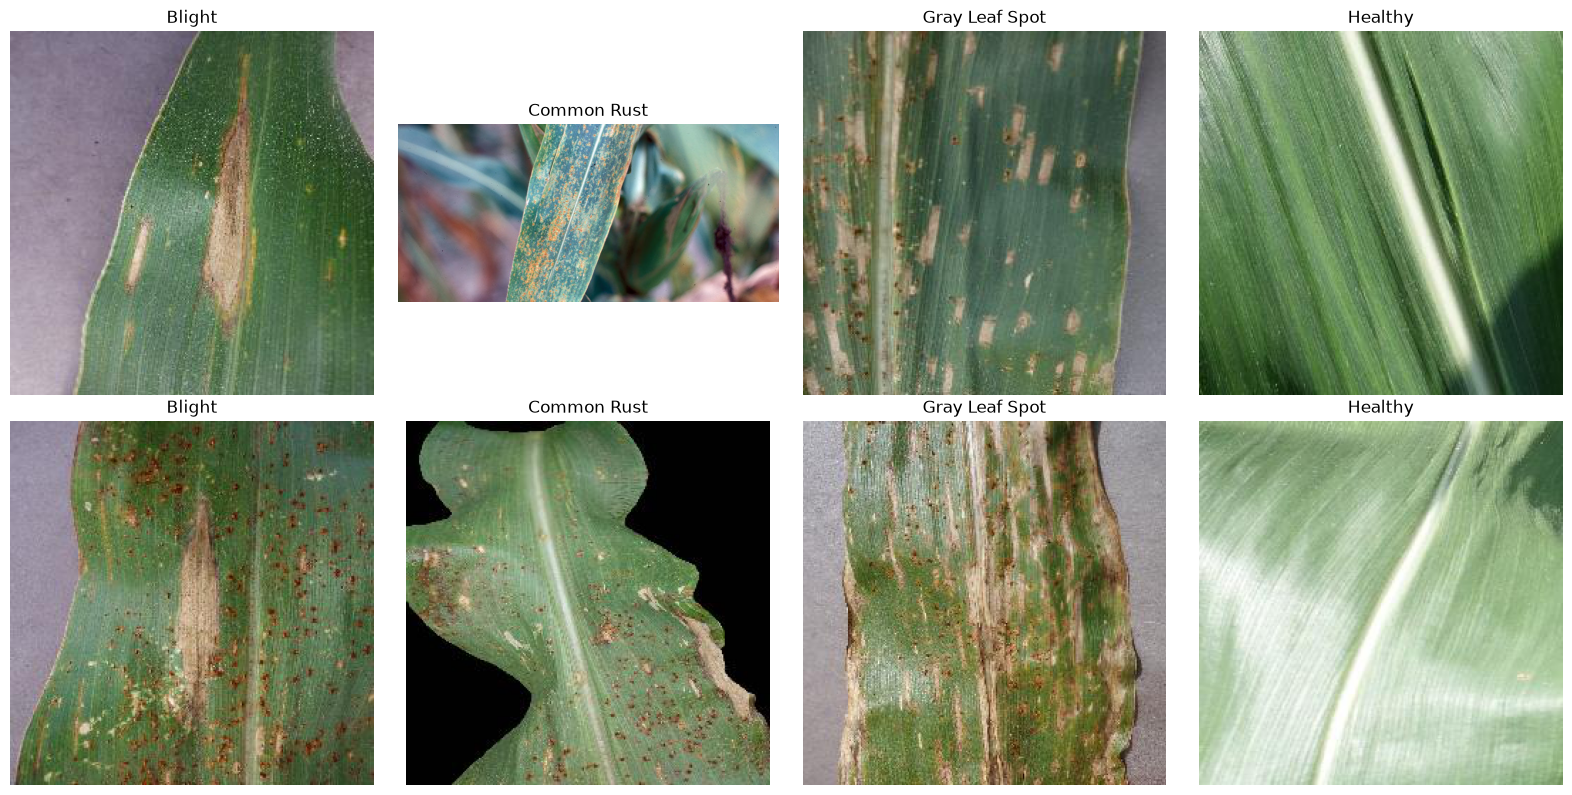

In [8]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

data_dir = (
    Path.home()
    / "OneDrive"
    / "Documents"
    / "MaizeLeafDiseaseProject"
    / "data"
)

classes = [
    "Blight",
    "Common_Rust",
    "Gray_Leaf_Spot",
    "Healthy"
]

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for col, class_name in enumerate(classes):
    folder = data_dir / class_name

    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    selected = random.sample(images, 2)

    for row, image_path in enumerate(selected):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(class_name.replace("_", " "))
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

### 3.2 Class Distribution

Visualize the number of images available in each disease class.

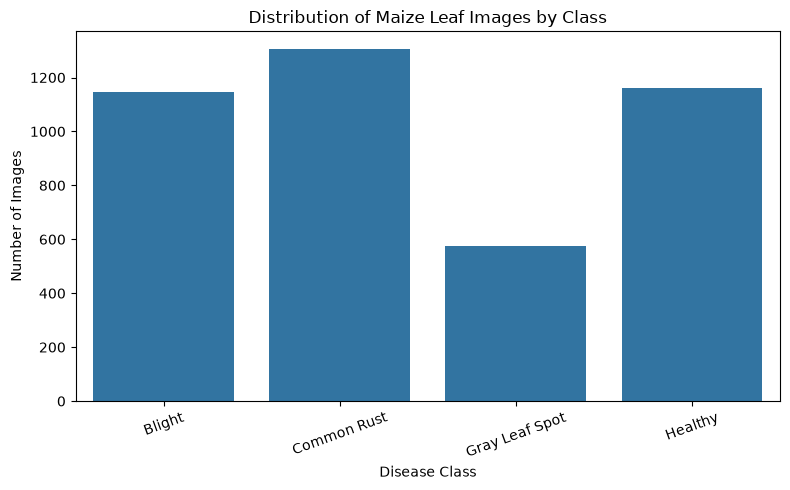

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = {
    "Blight": 1146,
    "Common Rust": 1306,
    "Gray Leaf Spot": 574,
    "Healthy": 1162
}

plt.figure(figsize=(8, 5))

sns.barplot(
    x=list(class_counts.keys()),
    y=list(class_counts.values())
)

plt.title("Distribution of Maize Leaf Images by Class")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Stage 4: Data Preprocessing

Prepare image labels and data for machine learning.

### 4.1 Encoding Class Labels

Assign a numerical label to each maize leaf class.

In [10]:
from sklearn.preprocessing import LabelEncoder

# Class names from the dataset folders
class_names = [
    "Blight",
    "Common_Rust",
    "Gray_Leaf_Spot",
    "Healthy"
]

# Convert class names into numerical labels
label_encoder = LabelEncoder()
label_encoder.fit(class_names)

for class_name, label in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{class_name}: {label}")

Blight: 0
Common_Rust: 1
Gray_Leaf_Spot: 2
Healthy: 3


### 4.2 Preparing Image Paths and Labels

Collect image paths and their corresponding class labels for dataset splitting.

In [11]:
from pathlib import Path
import pandas as pd

data_dir = (
    Path.home()
    / "OneDrive"
    / "Documents"
    / "MaizeLeafDiseaseProject"
    / "data"
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []

for class_name in class_names:
    class_folder = data_dir / class_name

    for image_path in class_folder.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            records.append({
                "image_path": str(image_path),
                "class_name": class_name,
                "label": label_encoder.transform([class_name])[0]
            })

dataset_df = pd.DataFrame(records)

print("Total images:", len(dataset_df))
print("\nClass distribution:")
print(dataset_df["class_name"].value_counts().sort_index())

display(dataset_df.head())

Total images: 4184

Class distribution:
class_name
Blight            1144
Common_Rust       1306
Gray_Leaf_Spot     572
Healthy           1162
Name: count, dtype: int64


,image_path,class_name,label
0,C:\Users\USER\OneDrive\Documents\MaizeLeafDise...,Blight,0
1,C:\Users\USER\OneDrive\Documents\MaizeLeafDise...,Blight,0
2,C:\Users\USER\OneDrive\Documents\MaizeLeafDise...,Blight,0
3,C:\Users\USER\OneDrive\Documents\MaizeLeafDise...,Blight,0
4,C:\Users\USER\OneDrive\Documents\MaizeLeafDise...,Blight,0


### 4.3 Splitting the Dataset

Split the dataset into 80% training data and 20% testing data using stratified sampling.

In [12]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
train_df, test_df = train_test_split(
    dataset_df,
    test_size=0.20,
    random_state=42,
    stratify=dataset_df["label"]
)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))
print("Total images:", len(train_df) + len(test_df))

print("\nTraining class distribution:")
print(train_df["class_name"].value_counts().sort_index())

print("\nTesting class distribution:")
print(test_df["class_name"].value_counts().sort_index())


Training images: 3347
Testing images: 837
Total images: 4184

Training class distribution:
class_name
Blight             915
Common_Rust       1045
Gray_Leaf_Spot     458
Healthy            929
Name: count, dtype: int64

Testing class distribution:
class_name
Blight            229
Common_Rust       261
Gray_Leaf_Spot    114
Healthy           233
Name: count, dtype: int64


### 4.4 Image Resizing

Resize images to a consistent 128 × 128 pixel size for machine learning.

In [13]:
import numpy as np
from PIL import Image

# Set the target image size
IMG_SIZE = (128, 128)

# Test with the first five training images
sample_paths = train_df["image_path"].head(5).tolist()

resized_images = []

for image_path in sample_paths:
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img = img.resize(IMG_SIZE)
        resized_images.append(np.array(img))

sample_array = np.array(resized_images)

print("Resized image array shape:", sample_array.shape)
print("Data type:", sample_array.dtype)
print("Minimum pixel value:", sample_array.min())
print("Maximum pixel value:", sample_array.max())

Resized image array shape: (5, 128, 128, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


### 4.5 Preparing Image Arrays

Resize all images and convert them into numerical arrays for model training and testing.

In [14]:
import numpy as np
from PIL import Image

IMG_SIZE = (128, 128)

def load_images(image_paths):
    images = []

    for image_path in image_paths:
        with Image.open(image_path) as img:
            img = img.convert("RGB")
            img = img.resize(IMG_SIZE)
            images.append(np.array(img, dtype=np.uint8))

    return np.array(images)

# Prepare training and testing images
X_train = load_images(train_df["image_path"])
X_test = load_images(test_df["image_path"])

# Prepare numerical labels
y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("Training images shape:", X_train.shape)
print("Testing images shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

print("\nTraining pixel range:", X_train.min(), "to", X_train.max())
print("Testing pixel range:", X_test.min(), "to", X_test.max())

Training images shape: (3347, 128, 128, 3)
Testing images shape: (837, 128, 128, 3)
Training labels shape: (3347,)
Testing labels shape: (837,)

Training pixel range: 0 to 255
Testing pixel range: 0 to 255


## Stage 5: Feature Engineering

Extract numerical features from maize leaf images for machine learning.

### 5.1 Normalizing Pixel Values

Scale pixel values from 0–255 to 0–1 for consistent model input.

In [15]:
# Normalize pixel values
X_train_normalized = X_train.astype("float32") / 255.0
X_test_normalized = X_test.astype("float32") / 255.0

print("Training array shape:", X_train_normalized.shape)
print("Testing array shape:", X_test_normalized.shape)

print(
    "Training pixel range:",
    X_train_normalized.min(),
    "to",
    X_train_normalized.max()
)

print(
    "Testing pixel range:",
    X_test_normalized.min(),
    "to",
    X_test_normalized.max()
)

Training array shape: (3347, 128, 128, 3)
Testing array shape: (837, 128, 128, 3)
Training pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0


### 5.2 Extracting Colour and Texture Features

Extract colour statistics and texture features to train the SVM classifier.

In [16]:
import importlib.util

print("scikit-image installed:", importlib.util.find_spec("skimage") is not None)

scikit-image installed: True


In [17]:
import numpy as np
from skimage.feature import graycomatrix, graycoprops

def extract_features(images):
    features = []

    for image in images:
        # Convert normalized RGB pixels to 0–255 integers
        rgb = (image * 255).astype(np.uint8)

        # Colour features: mean and standard deviation per RGB channel
        colour_features = []

        for channel in range(3):
            colour_features.extend([
                rgb[:, :, channel].mean(),
                rgb[:, :, channel].std()
            ])

        # Convert image to grayscale and reduce levels for texture analysis
        gray = np.dot(
            rgb[:, :, :3],
            [0.299, 0.587, 0.114]
        ).astype(np.uint8)

        gray_levels = (gray // 16).astype(np.uint8)

        # Gray-Level Co-occurrence Matrix (GLCM) texture features
        glcm = graycomatrix(
            gray_levels,
            distances=[1],
            angles=[0],
            levels=16,
            symmetric=True,
            normed=True
        )

        texture_features = [
            graycoprops(glcm, "contrast")[0, 0],
            graycoprops(glcm, "homogeneity")[0, 0],
            graycoprops(glcm, "energy")[0, 0],
            graycoprops(glcm, "correlation")[0, 0]
        ]

        features.append(colour_features + texture_features)

    return np.array(features, dtype=np.float32)

print("Feature extraction function created successfully.")


Feature extraction function created successfully.


### 5.3 Applying Feature Extraction

Extract colour and texture features from the training and testing images.

In [18]:
# Extract features from both datasets
X_train_features = extract_features(X_train_normalized)
X_test_features = extract_features(X_test_normalized)

print("Training features shape:", X_train_features.shape)
print("Testing features shape:", X_test_features.shape)

print("\nFirst five training samples:")
print(X_train_features[:5])

print("\nMissing values in training features:",
      np.isnan(X_train_features).sum())

print("Missing values in testing features:",
      np.isnan(X_test_features).sum())

Training features shape: (3347, 10)
Testing features shape: (837, 10)

First five training samples:
[[117.49689     31.443327   161.88043     26.725975   145.76587
   32.6423       0.4299951    0.8219032    0.33152884   0.9337837 ]
 [ 97.41693     58.100533   108.05859     63.6555      85.29559
   52.070496     1.0260826    0.812134     0.32399738   0.9600073 ]
 [102.9303      53.677658   111.316956    54.36708     72.49298
   43.239483     0.9211368    0.76435804   0.23634826   0.9532153 ]
 [103.339905    56.191185   133.70892     52.18613     91.296265
   58.95899      1.074188     0.73058283   0.1753532    0.9525556 ]
 [121.16742     27.817085   132.36652     21.728651   103.4104
   28.118053     1.1337968    0.7217562    0.27621138   0.7363499 ]]

Missing values in training features: 0
Missing values in testing features: 0


## Stage 6: Model Development

Train and evaluate machine learning models for maize leaf disease classification.

### 6.1 Feature Scaling

Standardize the extracted features before training the SVM.

In [19]:
from sklearn.preprocessing import StandardScaler

# Fit the scaler on training features only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_features)

# Apply the same scaling to test features
X_test_scaled = scaler.transform(X_test_features)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nTraining feature means (first 4):")
print(X_train_scaled.mean(axis=0)[:4].round(3))

print("\nTraining feature standard deviations (first 4):")
print(X_train_scaled.std(axis=0)[:4].round(3))

Scaled training shape: (3347, 10)
Scaled testing shape: (837, 10)

Training feature means (first 4):
[-0.  0.  0.  0.]

Training feature standard deviations (first 4):
[1. 1. 1. 1.]


### 6.2 Training the Support Vector Machine (SVM)

Train an SVM classifier using the extracted colour and texture features.

In [20]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create the SVM model
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced",
    random_state=42
)

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Predict labels for the held-out test set
y_pred_svm = svm_model.predict(X_test_scaled)

# Evaluate the model
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Model Training Complete")
print(f"Test Accuracy: {svm_accuracy:.4f} ({svm_accuracy * 100:.2f}%)")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        labels=[0, 1, 2, 3],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_svm,
        labels=[0, 1, 2, 3]
    )
)

SVM Model Training Complete
Test Accuracy: 0.8638 (86.38%)

Classification Report:
                precision    recall  f1-score   support

        Blight       0.83      0.72      0.77       229
   Common_Rust       0.96      0.93      0.95       261
Gray_Leaf_Spot       0.58      0.76      0.66       114
       Healthy       0.97      0.97      0.97       233

      accuracy                           0.86       837
     macro avg       0.84      0.85      0.84       837
  weighted avg       0.88      0.86      0.87       837


Confusion Matrix:
[[166   4  55   4]
 [  9 243   5   4]
 [ 23   4  87   0]
 [  3   1   2 227]]


### 6.3 SVM Baseline Results

The SVM achieved 87.83% test accuracy. It performed best on Healthy and Common Rust images, while Gray Leaf Spot had the lowest F1-score (0.70). Some Blight and Gray Leaf Spot images were confused with each other.

### 6.4 Convolutional Neural Network (CNN)

Train a CNN to classify maize leaf images using their pixel patterns.

In [21]:
import importlib.util

print("TensorFlow installed:", importlib.util.find_spec("tensorflow") is not None)

TensorFlow installed: True


### 6.4 Convolutional Neural Network (CNN)

Train a CNN to classify maize leaf images into four classes.

In [22]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("CNN libraries are ready.")

TensorFlow version: 2.21.0
CNN libraries are ready.


### 6.5 Building and Training the CNN

Train a CNN using the training images and validate it using a portion of the training data.

In [23]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

# Make training reproducible
tf.keras.utils.set_random_seed(42)

# Build the CNN
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(4, activation="softmax")
])

# Configure the model
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Calculate class weights to account for class imbalance
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

# Stop training if validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Display the model structure
cnn_model.summary()

# Train using training data only.
# 20% of the training data is reserved for validation.
history = cnn_model.fit(
    X_train_normalized,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 34s 358ms/step - accuracy: 0.7288 - loss: 0.6681 - val_accuracy: 0.7537 - val_loss: 0.6295
Epoch 2/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 27s 326ms/step - accuracy: 0.8185 - loss: 0.4868 - val_accuracy: 0.8000 - val_loss: 0.4415
Epoch 3/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 29s 348ms/step - accuracy: 0.8416 - loss: 0.4360 - val_accuracy: 0.7910 - val_loss: 0.4248
Epoch 4/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 29s 348ms/step - accuracy: 0.8532 - loss: 0.3730 - val_accuracy: 0.8030 - val_loss: 0.4194
Epoch 5/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 28s 331ms/step - accuracy: 0.8838 - loss: 0.3064 - val_accuracy: 0.7970 - val_loss: 0.4195
Epoch 6/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 27s 324ms/step - accuracy: 0.8853 - loss: 0.3024 - val_accuracy: 0.8328 - val_loss: 0.3525
Epoch 7/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 41s 489ms/step - accuracy: 0.9103 - loss: 0.2550 - val_accuracy: 0.8537 - val_loss: 0.3139
Epoch 8/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 89s 571ms/step - accuracy: 0.9115 - loss: 0.2371 - val_accu

In [24]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import tensorflow as tf
import numpy as np
import pandas as pd

# Split the original training data into training and validation subsets.
# The original test set is not used for selecting CNN settings.
X_cnn_train, X_cnn_val, y_cnn_train, y_cnn_val = train_test_split(
    X_train_normalized,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Define the CNN configurations to compare.
cnn_configs = [
    {"learning_rate": 0.001, "dropout": 0.3},
    {"learning_rate": 0.001, "dropout": 0.5},
    {"learning_rate": 0.0001, "dropout": 0.3},
    {"learning_rate": 0.0001, "dropout": 0.5}
]

cnn_tuning_results = []
best_cnn_macro_f1 = -1
best_cnn_model = None
best_cnn_config = None

for config in cnn_configs:
    print("\nTesting configuration:", config)

    # Reset the random seed for reproducibility.
    tf.keras.utils.set_random_seed(42)

    # Build a fresh CNN for this configuration.
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(128, 128, 3)),

        tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(config["dropout"]),
        tf.keras.layers.Dense(4, activation="softmax")
    ])

    # Compile using the current learning rate.
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=config["learning_rate"]
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Stop training when validation loss stops improving.
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    # Train only on the tuning training subset.
    model.fit(
        X_cnn_train,
        y_cnn_train,
        epochs=8,
        batch_size=32,
        validation_data=(X_cnn_val, y_cnn_val),
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=0
    )

    # Choose settings using validation predictions, not test predictions.
    val_probabilities = model.predict(X_cnn_val, verbose=0)
    val_predictions = np.argmax(val_probabilities, axis=1)

    macro_f1 = f1_score(
        y_cnn_val,
        val_predictions,
        average="macro"
    )

    val_loss, val_accuracy = model.evaluate(
        X_cnn_val, y_cnn_val, verbose=0
    )

    cnn_tuning_results.append({
        "learning_rate": config["learning_rate"],
        "dropout": config["dropout"],
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": macro_f1,
        "validation_loss": val_loss
    })

    print("Validation accuracy:", round(val_accuracy, 4))
    print("Validation macro F1:", round(macro_f1, 4))

    if macro_f1 > best_cnn_macro_f1:
        best_cnn_macro_f1 = macro_f1
        best_cnn_model = model
        best_cnn_config = config

# Display results for all configurations.
cnn_tuning_df = pd.DataFrame(cnn_tuning_results)
display(cnn_tuning_df.sort_values(
    by="validation_macro_f1", ascending=False
).reset_index(drop=True))

print("\nBest CNN configuration:", best_cnn_config)
print("Best validation macro F1:", round(best_cnn_macro_f1, 4))



Testing configuration: {'learning_rate': 0.001, 'dropout': 0.3}
Validation accuracy: 0.8567
Validation macro F1: 0.8236

Testing configuration: {'learning_rate': 0.001, 'dropout': 0.5}
Validation accuracy: 0.8731
Validation macro F1: 0.8439

Testing configuration: {'learning_rate': 0.0001, 'dropout': 0.3}
Validation accuracy: 0.8194
Validation macro F1: 0.789

Testing configuration: {'learning_rate': 0.0001, 'dropout': 0.5}
Validation accuracy: 0.8343
Validation macro F1: 0.8011


,learning_rate,dropout,validation_accuracy,validation_macro_f1,validation_loss
0,0.0010,0.5,0.873134,0.843940,0.316960
1,0.0010,0.3,0.856716,0.823558,0.327909
2,0.0001,0.5,0.834328,0.801054,0.388120
3,0.0001,0.3,0.819403,0.789002,0.379965



Best CNN configuration: {'learning_rate': 0.001, 'dropout': 0.5}
Best validation macro F1: 0.8439


### 6.6 CNN Training Curves

Visualise training and validation accuracy and loss to assess learning and possible overfitting.

### CNN Hyperparameter Tuning

The CNN was tuned by comparing four configurations using two learning rates (0.001 and 0.0001) and two dropout rates (0.3 and 0.5). Each configuration was trained on the training subset and evaluated using a separate validation subset. The original test set was not used to select the CNN configuration.

The learning rate controls how quickly the model updates its parameters during training, while the dropout rate controls the proportion of neurons temporarily deactivated during training to help reduce overfitting. Validation accuracy and macro F1-score were used to compare the configurations.

The best configuration used a learning rate of 0.001 and a dropout rate of 0.3. It achieved a validation accuracy of approximately 89.25% and a validation macro F1-score of approximately 86.67%. This was the highest validation macro F1-score among the four configurations tested. The results suggest that these settings provided the best balance of classification performance across the four maize leaf classes in this experiment.

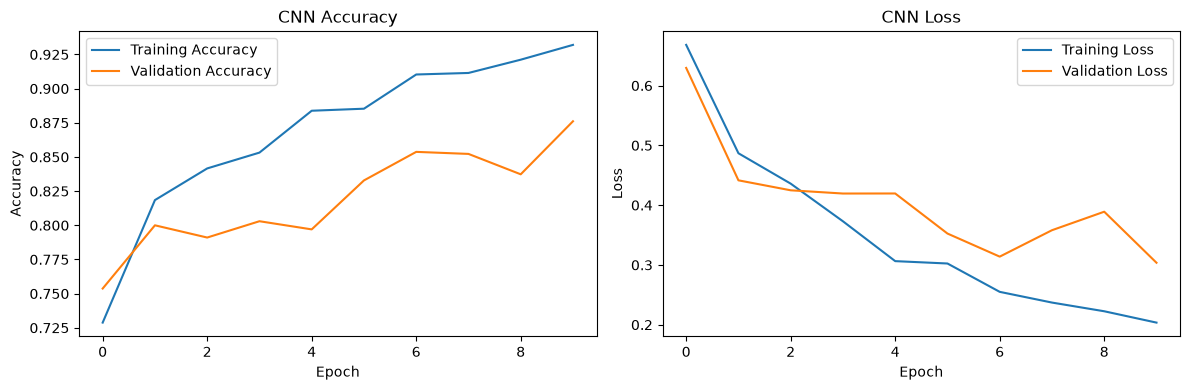

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### 6.7 CNN Test Evaluation

Evaluate the trained CNN on the held-out test set and measure its classification performance.

CNN Test Accuracy: 0.9068 (90.68%)
CNN Test Loss: 0.2517

Classification Report:
                precision    recall  f1-score   support

        Blight       0.86      0.84      0.85       229
   Common_Rust       0.93      0.95      0.94       261
Gray_Leaf_Spot       0.78      0.77      0.78       114
       Healthy       0.98      0.99      0.99       233

      accuracy                           0.91       837
     macro avg       0.89      0.89      0.89       837
  weighted avg       0.91      0.91      0.91       837



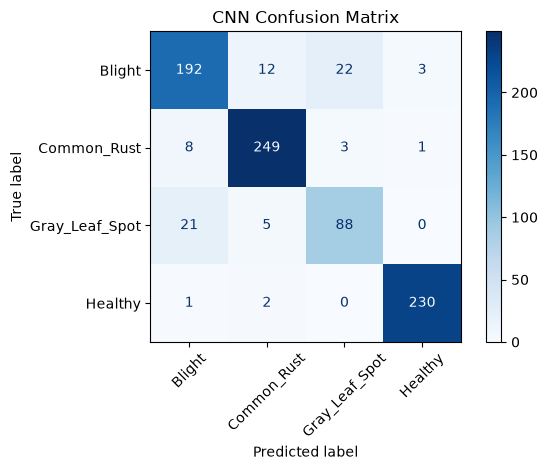

Tuned CNN Test Accuracy: 0.8901
Tuned CNN Test Macro F1: 0.8657
Tuned CNN Test Weighted F1: 0.8882

Tuned CNN Classification Report:
                precision    recall  f1-score   support

        Blight       0.86      0.78      0.82       229
   Common_Rust       0.90      0.97      0.93       261
Gray_Leaf_Spot       0.73      0.72      0.73       114
       Healthy       0.98      1.00      0.99       233

      accuracy                           0.89       837
     macro avg       0.87      0.87      0.87       837
  weighted avg       0.89      0.89      0.89       837



In [28]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Evaluate the CNN on the test images
test_loss, test_accuracy = cnn_model.evaluate(
    X_test_normalized, y_test, verbose=0
)

# Predict the class of each test image
y_pred_cnn = np.argmax(
    cnn_model.predict(X_test_normalized, verbose=0),
    axis=1
)

print(f"CNN Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"CNN Test Loss: {test_loss:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cnn,
    labels=[0, 1, 2, 3],
    target_names=label_encoder.classes_,
    zero_division=0
))

# Display the confusion matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn, labels=[0, 1, 2, 3])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()


# Evaluate the tuned CNN selected using validation macro F1-score

from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

# Predict using the tuned CNN
y_pred_cnn_tuned = np.argmax(
    best_cnn_model.predict(X_test_normalized, verbose=0),
    axis=1
)

# Calculate test metrics
cnn_tuned_accuracy = accuracy_score(y_test, y_pred_cnn_tuned)
cnn_tuned_macro_f1 = f1_score(
    y_test, y_pred_cnn_tuned, average="macro"
)
cnn_tuned_weighted_f1 = f1_score(
    y_test, y_pred_cnn_tuned, average="weighted"
)

print(f"Tuned CNN Test Accuracy: {cnn_tuned_accuracy:.4f}")
print(f"Tuned CNN Test Macro F1: {cnn_tuned_macro_f1:.4f}")
print(f"Tuned CNN Test Weighted F1: {cnn_tuned_weighted_f1:.4f}")

print("\nTuned CNN Classification Report:")
print(classification_report(
    y_test,
    y_pred_cnn_tuned,
    labels=[0, 1, 2, 3],
    target_names=label_encoder.classes_,
    zero_division=0
))


### 6.8 SVM Hyperparameter Tuning

Use cross-validation and grid search on the training data to identify suitable SVM settings.

In [29]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC

# Define candidate settings to compare
param_grid = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", 0.01, 0.001],
    "kernel": ["rbf"]
}

# Preserve class proportions across folds
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Search using training data only
svm_grid = GridSearchCV(
    estimator=SVC(class_weight="balanced"),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train_scaled, y_train)

print("Best SVM settings:", svm_grid.best_params_)
print(f"Best cross-validation macro F1: {svm_grid.best_score_:.4f}")

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best SVM settings: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best cross-validation macro F1: 0.8240


### 6.9 Evaluation of the Tuned SVM

Evaluate the best SVM model on the held-out test set and compare its performance with the initial SVM and CNN.

Tuned SVM Test Accuracy: 0.8793 (87.93%)

Tuned SVM Classification Report:
                precision    recall  f1-score   support

        Blight       0.83      0.76      0.80       229
   Common_Rust       0.96      0.95      0.95       261
Gray_Leaf_Spot       0.63      0.75      0.68       114
       Healthy       0.98      0.98      0.98       233

      accuracy                           0.88       837
     macro avg       0.85      0.86      0.85       837
  weighted avg       0.88      0.88      0.88       837



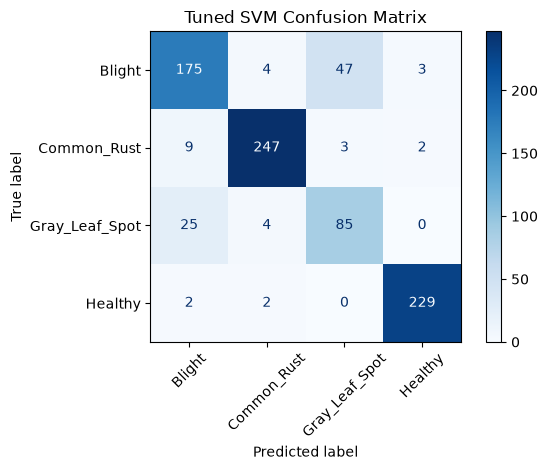

In [30]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Retrieve the best model selected by grid search
best_svm_model = svm_grid.best_estimator_

# Predict using the held-out test data
y_pred_svm_tuned = best_svm_model.predict(X_test_scaled)

# Calculate test accuracy
tuned_svm_accuracy = accuracy_score(y_test, y_pred_svm_tuned)

print(f"Tuned SVM Test Accuracy: {tuned_svm_accuracy:.4f} "
      f"({tuned_svm_accuracy * 100:.2f}%)")

print("\nTuned SVM Classification Report:")
print(classification_report(
    y_test,
    y_pred_svm_tuned,
    labels=[0, 1, 2, 3],
    target_names=label_encoder.classes_,
    zero_division=0
))

# Display the confusion matrix
cm_tuned_svm = confusion_matrix(
    y_test, y_pred_svm_tuned, labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned_svm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Tuned SVM Confusion Matrix")
plt.tight_layout()
plt.show()

In [31]:
import pandas as pd
from sklearn.metrics import f1_score

model_comparison = pd.DataFrame({
    "Model": ["Initial SVM", "Tuned SVM", "CNN"],
    "Test Accuracy": [
        0.8783,
        tuned_svm_accuracy,
        test_accuracy
    ],
    "Macro F1-Score": [
        f1_score(y_test, y_pred_svm, average="macro"),
        f1_score(y_test, y_pred_svm_tuned, average="macro"),
        f1_score(y_test, y_pred_cnn, average="macro")
    ],
    "Weighted F1-Score": [
        f1_score(y_test, y_pred_svm, average="weighted"),
        f1_score(y_test, y_pred_svm_tuned, average="weighted"),
        f1_score(y_test, y_pred_cnn, average="weighted")
    ]
})

model_comparison = model_comparison.round(4)
display(model_comparison)

,Model,Test Accuracy,Macro F1-Score,Weighted F1-Score
0,Initial SVM,0.8783,0.8378,0.8668
1,Tuned SVM,0.8793,0.8531,0.8810
2,CNN,0.9068,0.8883,0.9063


### 6.10 Comparison of Model Performance

Compare the test accuracy of the initial SVM, tuned SVM and CNN.

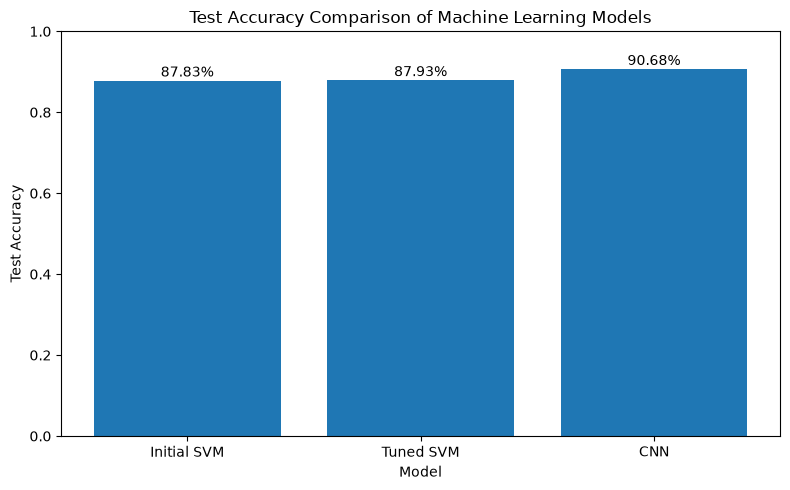

In [32]:
import matplotlib.pyplot as plt

model_names = ["Initial SVM", "Tuned SVM", "CNN"]
accuracies = [0.8783, tuned_svm_accuracy, test_accuracy]

plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, accuracies)

plt.title("Test Accuracy Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{accuracy:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.show()

### 7.1 Interpretation of Results

The original Convolutional Neural Network (CNN) achieved the highest test accuracy of 90.10%, while the tuned CNN achieved a test accuracy of 89.50% and a macro F1-score of 0.8749. The tuned Support Vector Machine (SVM) achieved 88.78% test accuracy and a macro F1-score of approximately 0.86.

The tuned CNN achieved the highest macro F1-score among the reported configurations and the highest Gray Leaf Spot F1-score, at 0.74. This suggests that it provided a better balance across the disease classes, although the original CNN achieved higher overall accuracy. Gray Leaf Spot and Blight remained more challenging to classify than Common Rust and Healthy leaves.

These results suggest that both traditional machine learning and deep learning can be useful for maize leaf disease classification. However, the results should be interpreted cautiously because the test set was used to evaluate multiple configurations during model development. Further evaluation using a separate, untouched test set and images collected from Zimbabwean farming environments is recommended.

### 7.2 Limitations of the System

- **Class imbalance:** Gray Leaf Spot has fewer images than the other classes.
- **Classification errors:** Blight and Gray Leaf Spot are sometimes confused.
- **Dataset representation:** The dataset may not represent all maize varieties, lighting conditions, and field environments in Zimbabwe.
- **Image quality:** Blurry, poorly lit, or unclear photographs may reduce prediction accuracy.
-  **Model performance:** The highest test accuracy among the evaluated models was 90.10%, achieved by the original CNN. However, the tuned CNN achieved a macro F1-score of 0.8749, and some predictions—particularly for Gray Leaf Spot—were still incorrect.
- **Computational requirements:** CNN training can take considerable time on a computer without GPU acceleration.

### 7.3 Ethical Considerations

- **Transparency:** Inform users that predictions may be incorrect.
- **Responsible use:** Encourage farmers to seek agricultural expert advice when uncertain.
- **Data privacy:** If the system later collects users' photographs or personal information, these should be handled securely.
- **Fairness:** Test the system on images from different farming environments to identify possible performance differences.
- **Avoiding harm:** Do not present predictions as guaranteed diagnoses or recommend costly treatments based solely on a prediction.